# Homework 5

Продолжаю работу с [TMDB 5000 Movie Dataset](https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata), использованным в Homework 3 и 4.

В работе выполняются:

- стандартизация и кластеризация K-Means для `k = 2…7`;
- выбор числа кластеров методом локтя и визуализация через PCA;
- поиск ассоциативных правил Apriori и сравнение TOP-5 по Support, Confidence и Lift;
- классификация фильмов по правилу `vote_average > 6` с/без стандартизации;
- матрица инцидентности ассоциативного графа и PageRank.

In [1]:
import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

import json
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyArrowPatch

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, log_loss, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

movies = pd.read_csv("tmdb_5000_movies.csv")
movies["release_date"] = pd.to_datetime(movies["release_date"], errors="coerce")
data = movies.loc[movies["vote_average"] > 0].copy()
data["release_year"] = data["release_date"].dt.year
data["good_movie"] = (data["vote_average"] > 6).astype(int)

for col in ["budget", "revenue", "runtime"]:
    data.loc[data[col] == 0, col] = np.nan

print("исходных фильмов:", len(movies))
print("фильмов с реальной оценкой:", len(data))
data[["title", "budget", "revenue", "popularity", "runtime", "vote_count", "vote_average"]].head()

исходных фильмов: 4803
фильмов с реальной оценкой: 4740


,title,budget,revenue,popularity,runtime,vote_count,vote_average
0,Avatar,237000000.0,2.787965e+09,150.437577,162.0,11800,7.2
1,Pirates of the Caribbean: At World's End,300000000.0,9.610000e+08,139.082615,169.0,4500,6.9
2,Spectre,245000000.0,8.806746e+08,107.376788,148.0,4466,6.3
3,The Dark Knight Rises,250000000.0,1.084939e+09,112.312950,165.0,9106,7.6
4,John Carter,260000000.0,2.841391e+08,43.926995,132.0,2124,6.1


## 1. Предобработка и стандартизация

Для кластеризации используются бюджет, сборы, популярность, длительность, число голосов и средняя оценка. Денежные и счётные признаки имеют длинные правые хвосты, поэтому сначала применяется `log(1 + x)`, затем пропуски заполняются медианами и все признаки приводятся к нулевому среднему и единичной дисперсии.

,log_budget,log_revenue,log_popularity,runtime,log_vote_count,vote_average
mean,0.000,0.000,0.000,-0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000
min,-9.417,-8.471,-2.246,-4.539,-2.530,-5.833
max,1.815,2.292,3.725,11.143,2.331,3.935


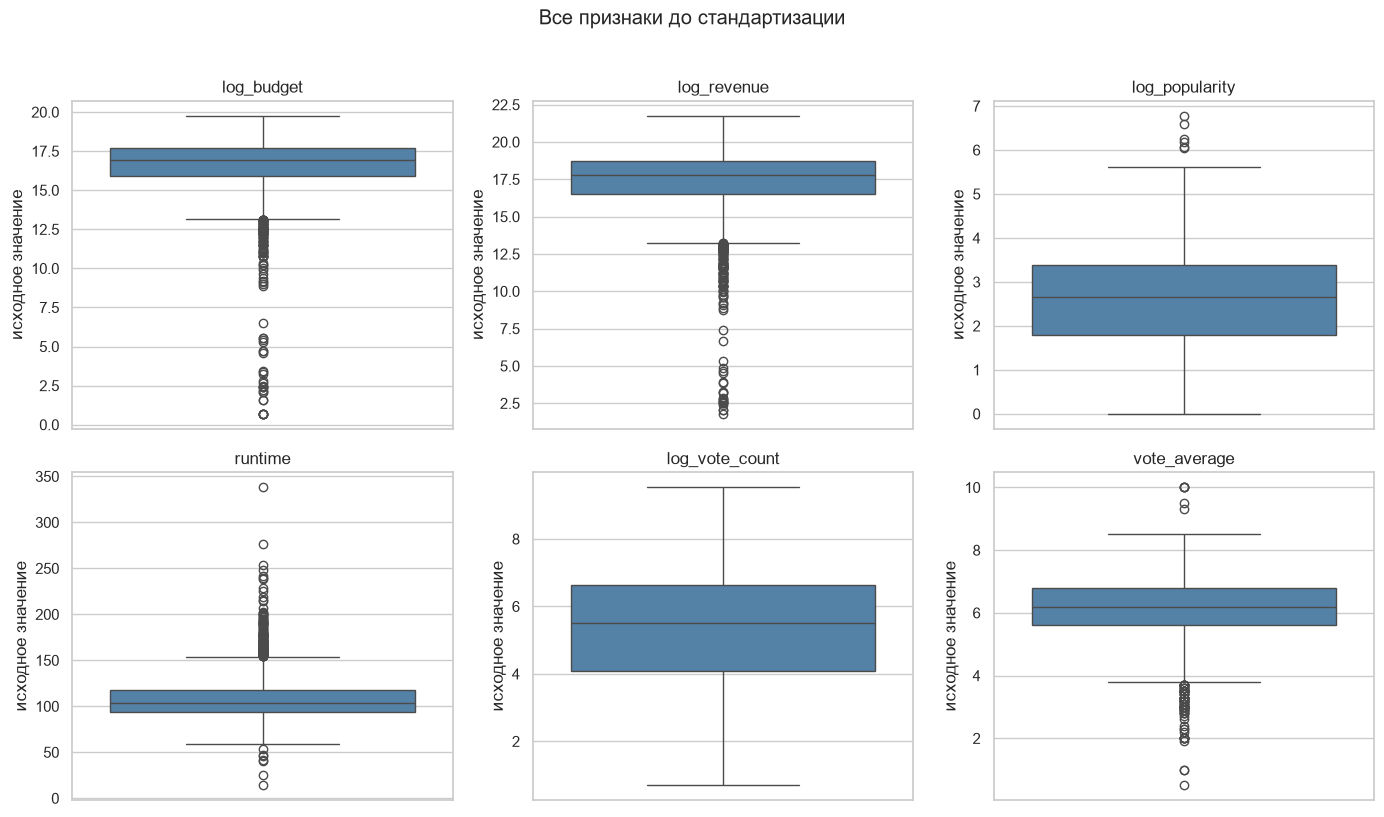

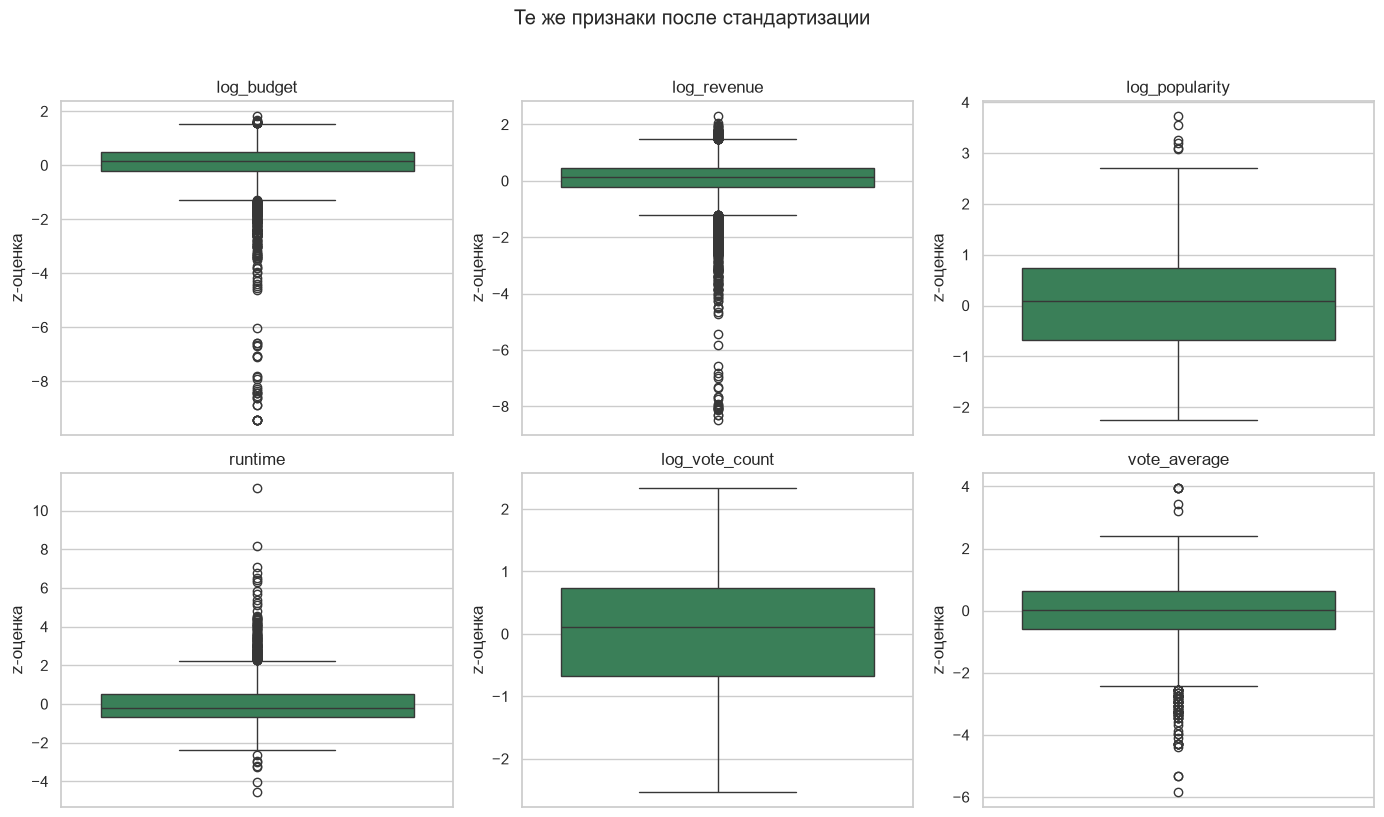

In [2]:
cluster_frame = pd.DataFrame(index=data.index)
cluster_frame["log_budget"] = np.log1p(data["budget"])
cluster_frame["log_revenue"] = np.log1p(data["revenue"])
cluster_frame["log_popularity"] = np.log1p(data["popularity"].clip(lower=0))
cluster_frame["runtime"] = data["runtime"]
cluster_frame["log_vote_count"] = np.log1p(data["vote_count"])
cluster_frame["vote_average"] = data["vote_average"]

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_imputed = imputer.fit_transform(cluster_frame)
X_scaled = scaler.fit_transform(X_imputed)

standardized = pd.DataFrame(X_scaled, columns=cluster_frame.columns, index=data.index)
display(standardized.agg(["mean", "std", "min", "max"]).round(3))

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, column in zip(axes.ravel(), cluster_frame.columns):
    sns.boxplot(y=cluster_frame[column], ax=ax, color="steelblue")
    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("исходное значение")
fig.suptitle("Все признаки до стандартизации", y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, column in zip(axes.ravel(), standardized.columns):
    sns.boxplot(y=standardized[column], ax=ax, color="seagreen")
    ax.set_title(column)
    ax.set_xlabel("")
    ax.set_ylabel("z-оценка")
fig.suptitle("Те же признаки после стандартизации", y=1.02)
plt.tight_layout()
plt.show()

**Интерпретация.** После преобразования средние всех признаков равны примерно нулю, а стандартные отклонения — единице. Бюджет и число голосов больше не доминируют над оценкой только из-за единиц измерения. Верхний набор графиков показывает все шесть исходных признаков на отдельных осях, потому что их единицы и масштабы сильно различаются. Нижний набор показывает те же признаки после приведения к общей z-шкале. Выбросы при этом сохраняются: например, у длительности есть фильмы более чем на 10 стандартных отклонений выше среднего. Стандартизация меняет масштаб, но не удаляет необычные наблюдения.

## 2. K-Means для k от 2 до 7 и метод локтя

Для каждого `k` рассчитывается inertia — сумма квадратов расстояний объектов до центров своих кластеров. Inertia уменьшается при увеличении числа кластеров. Число кластеров выбирается по точке изгиба графика, после которой дальнейшее уменьшение inertia становится менее заметным.

,k,inertia
0,2,20114.1176
1,3,17625.4484
2,4,15484.5129
3,5,14031.0275
4,6,12783.3389
5,7,11725.2011


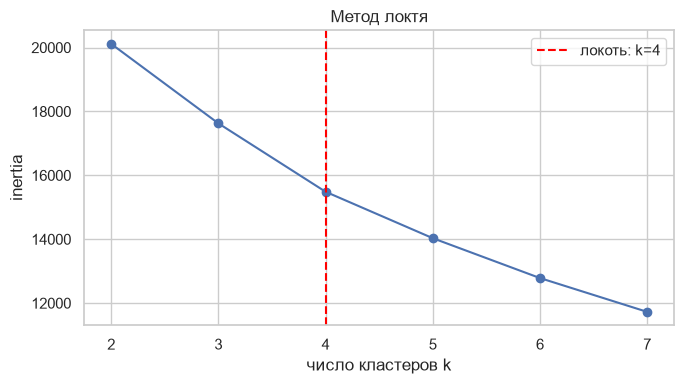

Выбранное число кластеров: 4


In [3]:
k_values = list(range(2, 8))
inertias = []
models = {}

for k in k_values:
    model = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    model.fit(X_scaled)
    models[k] = model
    inertias.append(model.inertia_)

# Автоматическая оценка точки максимального изгиба кривой метода локтя.
x = np.asarray(k_values, dtype=float)
y_inertia = np.asarray(inertias, dtype=float)
p1 = np.array([x[0], y_inertia[0]])
p2 = np.array([x[-1], y_inertia[-1]])
points = np.column_stack([x, y_inertia])
direction = p2 - p1
delta = points - p1
distances = np.abs(direction[0] * delta[:, 1] - direction[1] * delta[:, 0]) / np.linalg.norm(direction)
distances[[0, -1]] = -np.inf
chosen_k = int(x[np.argmax(distances)])

elbow_table = pd.DataFrame({"k": k_values, "inertia": inertias})
display(elbow_table.round(4))

plt.figure(figsize=(7, 4))
plt.plot(k_values, inertias, marker="o")
plt.axvline(chosen_k, color="red", linestyle="--", label=f"локоть: k={chosen_k}")
plt.xlabel("число кластеров k")
plt.ylabel("inertia")
plt.title("Метод локтя")
plt.legend()
plt.tight_layout()
plt.show()

print("Выбранное число кластеров:", chosen_k)


**Интерпретация метода локтя.** Наиболее заметный изгиб кривой inertia получен при `k=4`, поэтому для дальнейшего анализа выбраны четыре кластера. После `k=4` уменьшение inertia становится более плавным: добавление новых кластеров даёт уже меньший выигрыш и необоснованно усложняет сегментацию.

## 3. Визуализация и описание кластеров

Шесть стандартизированных признаков проецируются в двумерное пространство методом PCA. Цвет означает кластер, крест — центр кластера. Дополнительно строится тепловая карта средних стандартизированных признаков.

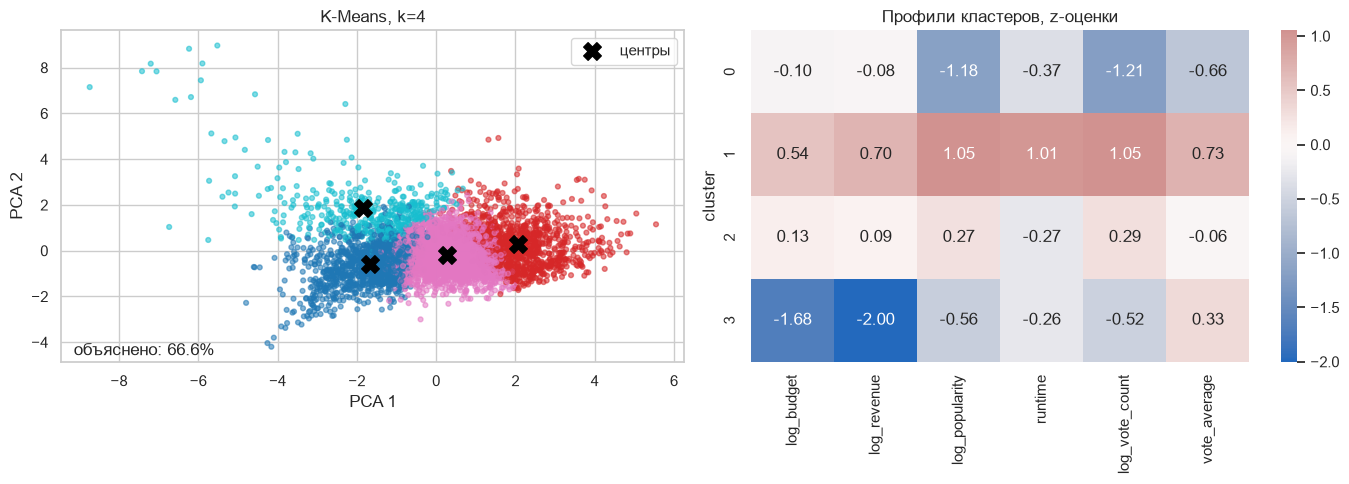

,фильмов,бюджет,сборы,популярность,длительность,голосов,оценка
cluster,,,,,,,
0,1234,10000000.0,12833495.5,2.66,97.0,25.0,5.6
1,1093,50000000.0,162045604.0,42.95,124.0,1486.0,6.9
2,1987,25000000.0,50305038.5,16.32,101.0,327.0,6.1
3,426,2000000.0,1477339.0,6.27,99.0,86.0,6.6


In [4]:
kmeans = models[chosen_k]
cluster_labels = kmeans.labels_
data["cluster"] = cluster_labels

pca = PCA(n_components=2, random_state=RANDOM_STATE)
coordinates = pca.fit_transform(X_scaled)
center_coordinates = pca.transform(kmeans.cluster_centers_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter = axes[0].scatter(
    coordinates[:, 0], coordinates[:, 1],
    c=cluster_labels, cmap="tab10", s=12, alpha=0.55,
)
axes[0].scatter(
    center_coordinates[:, 0], center_coordinates[:, 1],
    c="black", marker="X", s=160, label="центры",
)
axes[0].set_xlabel("PCA 1")
axes[0].set_ylabel("PCA 2")
axes[0].set_title(f"K-Means, k={chosen_k}")
axes[0].legend()
axes[0].text(
    0.02, 0.02,
    f"объяснено: {pca.explained_variance_ratio_.sum():.1%}",
    transform=axes[0].transAxes,
)

cluster_profile = standardized.assign(cluster=cluster_labels).groupby("cluster").mean()
sns.heatmap(cluster_profile, annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Профили кластеров, z-оценки")
plt.tight_layout()
plt.show()

cluster_summary = data.groupby("cluster").agg(
    фильмов=("id", "count"),
    бюджет=("budget", "median"),
    сборы=("revenue", "median"),
    популярность=("popularity", "median"),
    длительность=("runtime", "median"),
    голосов=("vote_count", "median"),
    оценка=("vote_average", "median"),
)
display(cluster_summary.round(2))

**Интерпретация кластеров.** Первые две компоненты PCA сохраняют 66.6 % информации, поэтому видимое перекрытие ожидаемо. Кластер 1 — крупные успешные фильмы: медианный бюджет 50 млн, сборы 162 млн, 1486 голосов и оценка 6.9; все его z-показатели положительны. Кластер 0 — малозаметные фильмы с низкой популярностью, 25 голосами и медианной оценкой 5.6. Кластер 2 — основной средний сегмент: 1987 фильмов, умеренные бюджет, сборы и оценка 6.1. Кластер 3 — малобюджетные фильмы с очень низкими сборами, но относительно высокой оценкой 6.6; это похоже на нишевое или независимое кино. Тепловая карта надёжнее PCA-графика для содержательного описания групп.

## 4. Подготовка транзакций для Apriori

Один фильм рассматривается как транзакция. В неё входят жанры, язык, десятилетие выхода, класс оценки, категории бюджета, сборов, популярности и длительности. Непрерывные показатели разбиваются на квартильные категории, рассчитанные по текущему файлу.

In [5]:
def json_names(value):
    try:
        return [item["name"] for item in json.loads(value)]
    except (TypeError, ValueError, KeyError):
        return []


def quantile_labels(series, prefix):
    ranked = series.rank(method="first")
    return pd.qcut(ranked, 4, labels=[
        f"{prefix}=низкий", f"{prefix}=ниже среднего",
        f"{prefix}=выше среднего", f"{prefix}=высокий",
    ])


transaction_frame = pd.DataFrame(index=data.index)
transaction_frame["budget_band"] = quantile_labels(data["budget"].fillna(data["budget"].median()), "бюджет")
transaction_frame["revenue_band"] = quantile_labels(data["revenue"].fillna(data["revenue"].median()), "сборы")
transaction_frame["popularity_band"] = quantile_labels(data["popularity"], "популярность")
transaction_frame["runtime_band"] = pd.cut(
    data["runtime"].fillna(data["runtime"].median()),
    bins=[0, 90, 120, np.inf],
    labels=["длительность=короткий", "длительность=средний", "длительность=длинный"],
)
transaction_frame["rating_band"] = np.where(data["vote_average"] > 6, "оценка=хорошая", "оценка=не выше 6")
transaction_frame["decade"] = (data["release_year"] // 10 * 10).fillna(-1).astype(int).astype(str).radd("десятилетие=")
top_languages = set(data["original_language"].value_counts().head(6).index)

transactions = []
for idx, row in data.iterrows():
    items = set()
    for genre in json_names(row["genres"]):
        items.add(f"жанр={genre}")
    language = row["original_language"] if row["original_language"] in top_languages else "other"
    items.add(f"язык={language}")
    for column in transaction_frame.columns:
        items.add(str(transaction_frame.loc[idx, column]))
    transactions.append(frozenset(items))

lengths = pd.Series([len(t) for t in transactions])
print("транзакций:", len(transactions))
print("элементов в транзакции — min/median/max:", lengths.min(), lengths.median(), lengths.max())
print("пример:")
print(sorted(transactions[0]))

транзакций: 4740
элементов в транзакции — min/median/max: 7 10.0 14
пример:
['бюджет=высокий', 'десятилетие=2000', 'длительность=длинный', 'жанр=Action', 'жанр=Adventure', 'жанр=Fantasy', 'жанр=Science Fiction', 'оценка=хорошая', 'популярность=высокий', 'сборы=высокий', 'язык=en']


## 5. Apriori и пороги правил

Перебираются наборы длины 1–3. Выбраны пороги:

- `Support ≥ 0.03` — правило встречается минимум примерно у 142 фильмов;
- `Confidence ≥ 0.35` — следствие выполняется минимум в 35 % случаев выполнения условия;
- `Lift > 1.05` — совместная встречаемость минимум на 5 % выше независимого случая.

Это оставляет достаточно правил для сравнения, но отсекает редкие и почти независимые связи.

In [6]:
MIN_SUPPORT = 0.03
MIN_CONFIDENCE = 0.35
MIN_LIFT = 1.05
N = len(transactions)

counts = Counter()
for transaction in transactions:
    ordered = sorted(transaction)
    for size in [1, 2, 3]:
        counts.update(combinations(ordered, size))

frequent = {
    itemset: count / N
    for itemset, count in counts.items()
    if count / N >= MIN_SUPPORT
}

rule_rows = []
for itemset, support in frequent.items():
    if len(itemset) < 2:
        continue
    itemset_set = set(itemset)
    for left_size in range(1, len(itemset)):
        for left_tuple in combinations(itemset, left_size):
            left = tuple(sorted(left_tuple))
            right = tuple(sorted(itemset_set - set(left)))
            left_support = frequent.get(left, counts[left] / N)
            right_support = frequent.get(right, counts[right] / N)
            confidence = support / left_support
            lift = confidence / right_support
            if confidence >= MIN_CONFIDENCE and lift > MIN_LIFT:
                rule_rows.append({
                    "условие": " & ".join(left),
                    "рекомендация": " & ".join(right),
                    "Support": support,
                    "Confidence": confidence,
                    "Lift": lift,
                    "условие_items": left,
                    "рекомендация_items": right,
                })

rules = pd.DataFrame(rule_rows).drop_duplicates(
    subset=["условие", "рекомендация"]
).reset_index(drop=True)

print("частых наборов:", len(frequent))
print("правил после порогов:", len(rules))
display(rules[["условие", "рекомендация", "Support", "Confidence", "Lift"]].head(10).round(3))

частых наборов: 1396
правил после порогов: 1354


,условие,рекомендация,Support,Confidence,Lift
0,бюджет=высокий,десятилетие=2000,0.119,0.478,1.113
1,бюджет=высокий,длительность=длинный,0.088,0.353,1.697
2,длительность=длинный,бюджет=высокий,0.088,0.424,1.697
3,бюджет=высокий,жанр=Action,0.110,0.441,1.821
4,жанр=Action,бюджет=высокий,0.110,0.455,1.821
5,бюджет=высокий,жанр=Adventure,0.091,0.365,2.187
6,жанр=Adventure,бюджет=высокий,0.091,0.547,2.187
7,жанр=Fantasy,бюджет=высокий,0.048,0.540,2.160
8,жанр=Science Fiction,бюджет=высокий,0.049,0.431,1.723
9,бюджет=высокий,популярность=высокий,0.135,0.542,2.167


## 6. TOP-5 рекомендаций по разным метрикам

Support отдаёт предпочтение массовым закономерностям, Confidence — надёжным следствиям, Lift — наиболее необычным совместным появлениям относительно независимого случая.

TOP-5 по Support


,условие,рекомендация,Support,Confidence,Lift
328,жанр=Drama,оценка=хорошая,0.339,0.707,1.216
329,оценка=хорошая,жанр=Drama,0.339,0.583,1.216
397,жанр=Drama,оценка=хорошая & язык=en,0.305,0.636,1.190
398,оценка=хорошая,жанр=Drama & язык=en,0.305,0.525,1.198
399,жанр=Drama & язык=en,оценка=хорошая,0.305,0.696,1.198


TOP-5 по Confidence


,условие,рекомендация,Support,Confidence,Lift
251,жанр=Science Fiction & сборы=высокий,язык=en,0.042,1.000,1.066
285,бюджет=высокий & жанр=Crime,язык=en,0.040,1.000,1.066
409,жанр=Thriller & сборы=высокий,язык=en,0.070,1.000,1.066
597,бюджет=высокий & жанр=Romance,язык=en,0.032,1.000,1.066
558,бюджет=высокий & жанр=Comedy,язык=en,0.081,0.997,1.063


TOP-5 по Lift


,условие,рекомендация,Support,Confidence,Lift
480,жанр=Family,жанр=Animation & язык=en,0.039,0.359,8.177
481,жанр=Animation & язык=en,жанр=Family,0.039,0.880,8.177
450,жанр=Animation,жанр=Family,0.041,0.833,7.745
451,жанр=Family,жанр=Animation,0.041,0.382,7.745
479,жанр=Animation,жанр=Family & язык=en,0.039,0.782,7.534


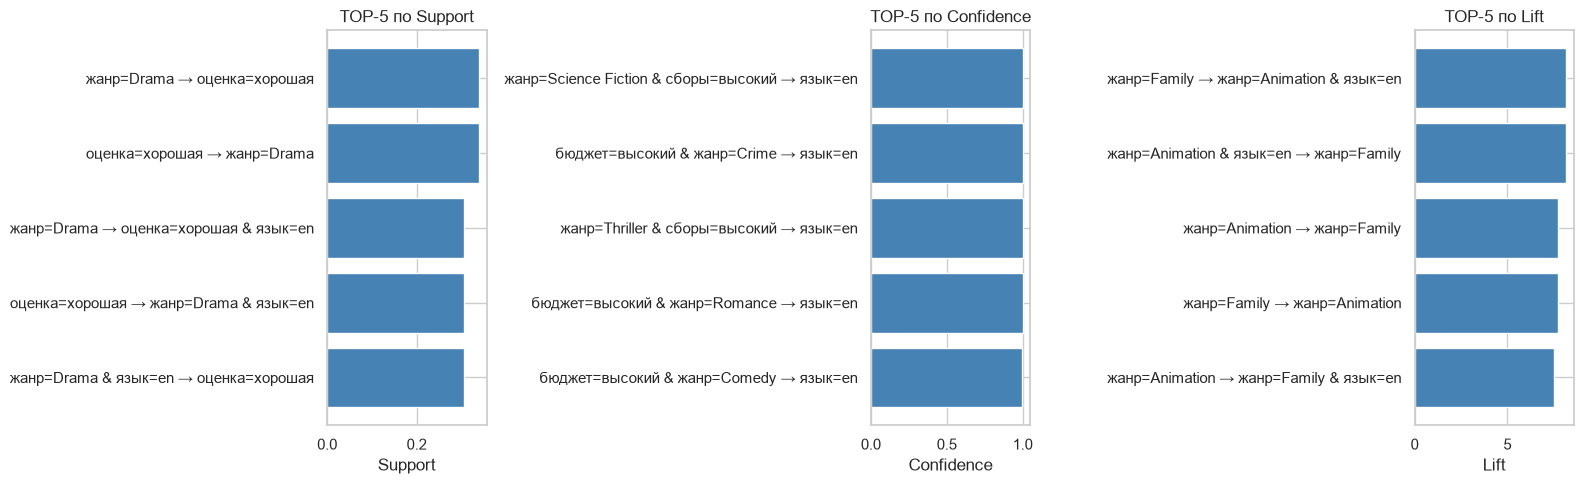

In [7]:
top_support = rules.nlargest(5, "Support")
top_confidence = rules.nlargest(5, "Confidence")
top_lift = rules.nlargest(5, "Lift")

print("TOP-5 по Support")
display(top_support[["условие", "рекомендация", "Support", "Confidence", "Lift"]].round(3))
print("TOP-5 по Confidence")
display(top_confidence[["условие", "рекомендация", "Support", "Confidence", "Lift"]].round(3))
print("TOP-5 по Lift")
display(top_lift[["условие", "рекомендация", "Support", "Confidence", "Lift"]].round(3))

top_union = pd.concat([
    top_support.assign(критерий="Support"),
    top_confidence.assign(критерий="Confidence"),
    top_lift.assign(критерий="Lift"),
]).drop_duplicates(subset=["условие", "рекомендация", "критерий"])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (metric, top) in zip(
    axes,
    [("Support", top_support), ("Confidence", top_confidence), ("Lift", top_lift)],
):
    labels = (top["условие"] + " → " + top["рекомендация"]).str.slice(0, 55)
    ax.barh(labels[::-1], top[metric][::-1], color="steelblue")
    ax.set_title(f"TOP-5 по {metric}")
    ax.set_xlabel(metric)
plt.tight_layout()
plt.show()

**Интерпретация правил.** По Support лидирует правило `Drama → хорошая оценка`: оно встречается у 33.9 % фильмов, Confidence = 0.707 и Lift = 1.216, поэтому связь массовая и умеренно полезная. TOP по Confidence почти полностью состоит из правил, заканчивающихся `язык=en`: Confidence достигает 1, но Lift около 1.066, так как английский язык и без условия очень распространён. Такие рекомендации надёжны, но малоинформативны. По Lift лидирует связь Family и Animation: Lift достигает 8.177, что означает совместную встречаемость примерно в восемь раз чаще независимого случая. Она выглядит логично и содержательно. Необычные правила чаще появляются из-за редких жанровых сочетаний, квартильного разбиения и особенностей состава TMDB, а не из-за причинной зависимости.

## Дополнительная часть +1: классификация с/без стандартизации

Целевой класс строится из одного признака: `vote_average > 6`. Сам `vote_average` исключается из входных данных. kNN, SVM и Logistic Regression обучаются:

1. на исходных числовых масштабах после заполнения пропусков;
2. на тех же данных после `StandardScaler`.

Используются одинаковые train/test и метрики Homework 3–4.

,Accuracy,F1,LogLoss,ROC-AUC
"kNN, стандартизация",0.7089,0.7491,0.6241,0.7678
"Logistic Regression, стандартизация",0.6941,0.7354,0.5777,0.7592
"SVM, стандартизация",0.6983,0.7307,0.5572,0.7745
"Logistic Regression, без стандартизации",0.6814,0.7289,0.5840,0.7540
"SVM, без стандартизации",0.5791,0.7235,0.6729,0.5979
"kNN, без стандартизации",0.6224,0.6849,0.7415,0.6565


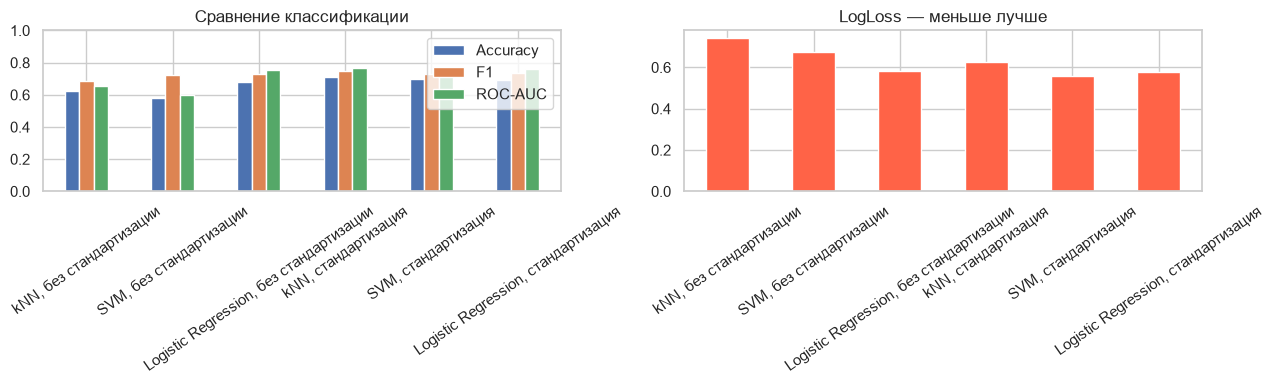

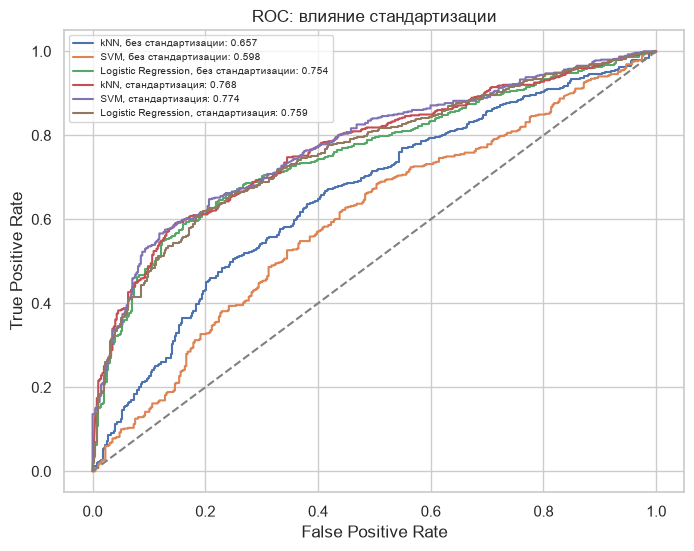

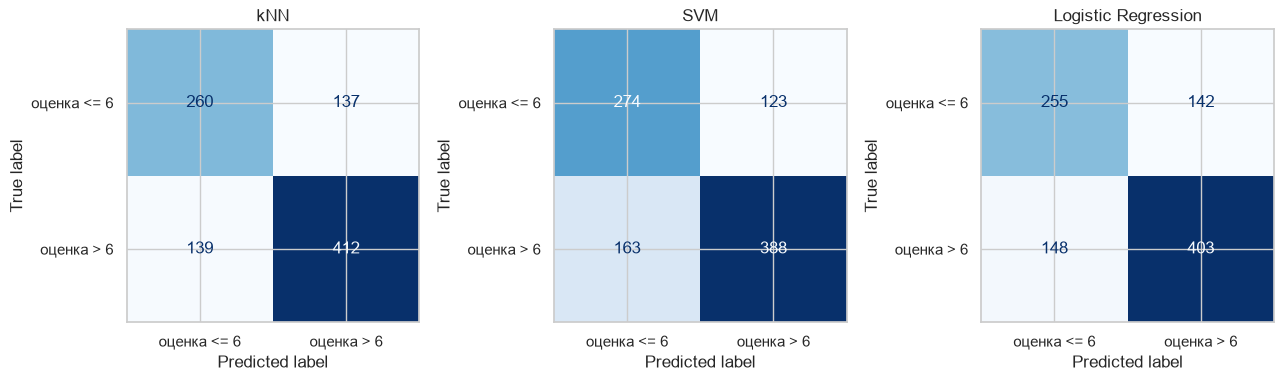

Лучший F1 у kNN, стандартизация: F1=0.749, Accuracy=0.709.


In [8]:
classification_features = [
    "budget", "revenue", "popularity", "runtime", "vote_count", "release_year",
]
X_class = data[classification_features]
y_class = data["good_movie"]
train_idx, test_idx = train_test_split(
    data.index,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_class,
)
X_train, X_test = X_class.loc[train_idx], X_class.loc[test_idx]
y_train, y_test = y_class.loc[train_idx], y_class.loc[test_idx]


def classifiers(standardized):
    prep = [SimpleImputer(strategy="median")]
    if standardized:
        prep.append(StandardScaler())
    return {
        "kNN": make_pipeline(*prep, KNeighborsClassifier(n_neighbors=15, weights="distance")),
        "SVM": make_pipeline(*prep, SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)),
        "Logistic Regression": make_pipeline(
            *prep, LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
        ),
    }


def classification_scores(real, labels, probabilities):
    probabilities = np.clip(probabilities, 1e-7, 1 - 1e-7)
    return {
        "Accuracy": accuracy_score(real, labels),
        "F1": f1_score(real, labels),
        "LogLoss": log_loss(real, probabilities, labels=[0, 1]),
        "ROC-AUC": roc_auc_score(real, probabilities),
    }


all_labels = {}
all_probabilities = {}
rows = {}
for variant, use_scaler in [("без стандартизации", False), ("стандартизация", True)]:
    for name, model in classifiers(use_scaler).items():
        model.fit(X_train, y_train)
        key = f"{name}, {variant}"
        labels = model.predict(X_test)
        probabilities = model.predict_proba(X_test)[:, 1]
        all_labels[key] = labels
        all_probabilities[key] = probabilities
        rows[key] = classification_scores(y_test, labels, probabilities)

classification_table = pd.DataFrame(rows).T
display(classification_table.sort_values("F1", ascending=False).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
classification_table[["Accuracy", "F1", "ROC-AUC"]].plot(
    kind="bar", ylim=(0, 1), ax=axes[0]
)
axes[0].set_title("Сравнение классификации")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=35)
classification_table["LogLoss"].plot(kind="bar", color="tomato", ax=axes[1])
axes[1].set_title("LogLoss — меньше лучше")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for name, probability in all_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probability)
    plt.plot(fpr, tpr, label=f"{name}: {roc_auc_score(y_test, probability):.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC: влияние стандартизации")
plt.legend(fontsize=7)
plt.show()

standard_labels = {
    name: values for name, values in all_labels.items() if name.endswith("стандартизация")
}
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, labels) in zip(axes, standard_labels.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, labels),
        display_labels=["оценка <= 6", "оценка > 6"],
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name.replace(", стандартизация", ""))
plt.tight_layout()
plt.show()

best_classification = classification_table["F1"].idxmax()
print(
    f"Лучший F1 у {best_classification}: "
    f"F1={classification_table.loc[best_classification, 'F1']:.3f}, "
    f"Accuracy={classification_table.loc[best_classification, 'Accuracy']:.3f}."
)

**Интерпретация классификации.** Стандартизация улучшила все три метода. У kNN Accuracy выросла с 0.622 до 0.709, F1 — с 0.685 до 0.749, ROC-AUC — с 0.657 до 0.768. У SVM особенно заметно вырос ROC-AUC: с 0.598 до 0.775; без стандартизации модель почти определяется масштабом бюджета и сборов. Logistic Regression изменилась слабее: Accuracy выросла с 0.681 до 0.694. Лучший F1 = 0.749 получил стандартизированный kNN, а лучший ROC-AUC = 0.775 — стандартизированная SVM. По матрицам ошибок kNN лучше находит хорошие фильмы, а SVM правильнее распознаёт класс с оценкой не выше 6.

## Дополнительная часть +2: матрица инцидентности и PageRank

Граф строится по одноэлементным ассоциативным правилам `A → B`, прошедшим те же пороги. Вершины — признаки транзакций, ориентированное ребро — правило. Вес ребра равен `Lift × Confidence`: Lift отражает необычность связи, Confidence — её надёжность. Матрица инцидентности содержит `−w` у начала ребра и `+w` у конца.

вершин: 36 рёбер: 139


,e0,e1,e2,e3,e4,e5,e6,e7,e8,e9
бюджет=высокий,0.0,0.0,0.0,0.0,0.0,-1.72,1.72,0.0,0.0,0.0
бюджет=выше среднего,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0
бюджет=ниже среднего,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0
бюджет=низкий,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0
десятилетие=1980,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0
десятилетие=1990,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0
десятилетие=2000,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0
десятилетие=2010,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0
длительность=длинный,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0
длительность=короткий,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0


,PageRank
жанр=Comedy,0.1467
оценка=хорошая,0.1448
жанр=Drama,0.1422
длительность=средний,0.1229
оценка=не выше 6,0.1210
десятилетие=2000,0.0464
сборы=высокий,0.0247
популярность=высокий,0.0242
бюджет=высокий,0.0241
жанр=Action,0.0195


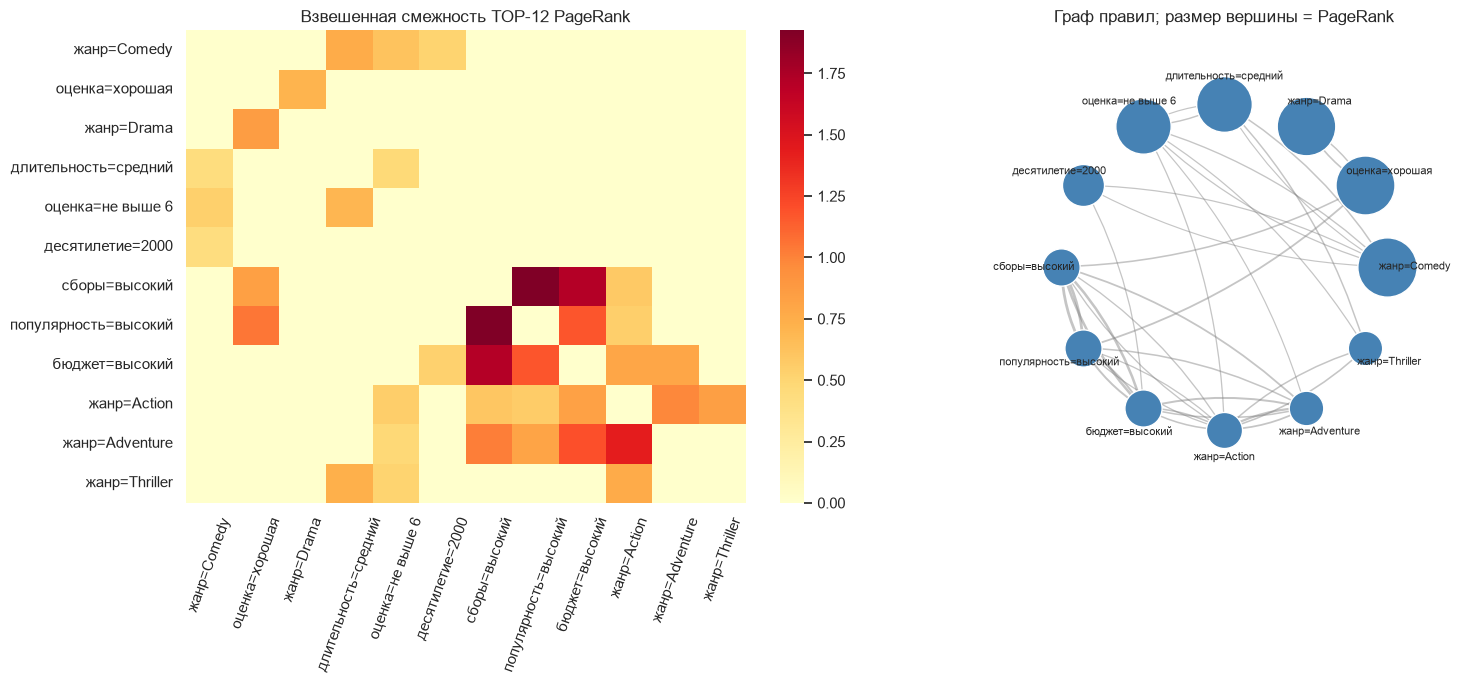

In [9]:
pair_rules = rules[
    rules["условие_items"].map(len).eq(1)
    & rules["рекомендация_items"].map(len).eq(1)
].copy()
pair_rules["from"] = pair_rules["условие_items"].str[0]
pair_rules["to"] = pair_rules["рекомендация_items"].str[0]
pair_rules["weight"] = pair_rules["Lift"] * pair_rules["Confidence"]

# Для каждой пары направлений оставляем наиболее сильное правило.
edges = pair_rules.sort_values("weight", ascending=False).drop_duplicates(["from", "to"])
nodes = sorted(set(edges["from"]) | set(edges["to"]))
node_index = {node: i for i, node in enumerate(nodes)}

incidence = np.zeros((len(nodes), len(edges)))
for edge_number, (_, row) in enumerate(edges.iterrows()):
    incidence[node_index[row["from"]], edge_number] = -row["weight"]
    incidence[node_index[row["to"]], edge_number] = row["weight"]

incidence_frame = pd.DataFrame(
    incidence,
    index=nodes,
    columns=[f"e{i}" for i in range(len(edges))],
)
print("вершин:", len(nodes), "рёбер:", len(edges))
display(incidence_frame.iloc[:10, :10].round(2))

# Взвешенный PageRank.
adjacency = np.zeros((len(nodes), len(nodes)))
for _, row in edges.iterrows():
    adjacency[node_index[row["from"]], node_index[row["to"]]] += row["weight"]

row_sums = adjacency.sum(axis=1)
transition = np.divide(
    adjacency,
    row_sums[:, None],
    out=np.zeros_like(adjacency),
    where=row_sums[:, None] != 0,
)
dangling = row_sums == 0
transition[dangling] = 1 / len(nodes)

damping = 0.85
pagerank = np.full(len(nodes), 1 / len(nodes))
for _ in range(1000):
    updated = (1 - damping) / len(nodes) + damping * transition.T @ pagerank
    if np.abs(updated - pagerank).sum() < 1e-12:
        break
    pagerank = updated

pagerank_series = pd.Series(pagerank, index=nodes).sort_values(ascending=False)
display(pagerank_series.head(15).rename("PageRank").to_frame().round(4))

top_nodes = list(pagerank_series.head(12).index)
top_edges = edges[edges["from"].isin(top_nodes) & edges["to"].isin(top_nodes)].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.heatmap(
    adjacency[[node_index[n] for n in top_nodes]][:, [node_index[n] for n in top_nodes]],
    xticklabels=top_nodes, yticklabels=top_nodes,
    cmap="YlOrRd", ax=axes[0],
)
axes[0].set_title("Взвешенная смежность TOP-12 PageRank")
axes[0].tick_params(axis="x", rotation=70)

angles = np.linspace(0, 2 * np.pi, len(top_nodes), endpoint=False)
positions = {node: np.array([np.cos(a), np.sin(a)]) for node, a in zip(top_nodes, angles)}
for _, row in top_edges.iterrows():
    start, end = positions[row["from"]], positions[row["to"]]
    arrow = FancyArrowPatch(
        start, end,
        arrowstyle="-|>", mutation_scale=10,
        linewidth=0.5 + 1.5 * row["weight"] / top_edges["weight"].max(),
        color="gray", alpha=0.45,
        connectionstyle="arc3,rad=0.12",
    )
    axes[1].add_patch(arrow)
for node, position in positions.items():
    size = 500 + 9000 * pagerank_series[node]
    axes[1].scatter(*position, s=size, color="steelblue", edgecolor="white", zorder=3)
    axes[1].text(*(position * 1.17), node, ha="center", va="center", fontsize=8)
axes[1].set_xlim(-1.45, 1.45)
axes[1].set_ylim(-1.45, 1.45)
axes[1].set_aspect("equal")
axes[1].axis("off")
axes[1].set_title("Граф правил; размер вершины = PageRank")
plt.tight_layout()
plt.show()